# [기초-실습] 통계 101x데이터 분석: (5-6장) 다양한 가설검정

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [ ]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!pip install statsmodels
#!sudo apt-get install -y fonts-nanum
#!sudo fc-cache -fv
#!rm ~/.cache/matplotlib -rf

You should consider upgrading via the 'C:\Users\user\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.
Sudo가 이 컴퓨터에서 사용하지 않도록 설정되어 있습니다. 사용하도록 설정하려면 으로 이동하세요. ]8;;ms-settings:developers\Developer Settings page]8;;\ 설정 앱의
Sudo가 이 컴퓨터에서 사용하지 않도록 설정되어 있습니다. 사용하도록 설정하려면 으로 이동하세요. ]8;;ms-settings:developers\Developer Settings page]8;;\ 설정 앱의
'rm'��(��) ���� �Ǵ� �ܺ� ����, ������ �� �ִ� ���α׷�, �Ǵ�
��ġ ������ �ƴմϴ�.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [17]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = ['Malgun Gothic', 'DejaVu Sans']  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

In [14]:
import matplotlib.font_manager as fm
print([f.name for f in fm.fontManager.ttflist if 'Malgun' in f.name])

['Malgun Gothic', 'Malgun Gothic', 'Malgun Gothic Semilight', 'Malgun Gothic']


# 문제 1. 게임 아이템 뽑기 확률, 정말 10%일까? (난이도: 하)

**📘 문제**

- 어떤 게임 개발사에서 새로운 아이템의 뽑기 확률이 **10%**로 설정되었다고 주장하고 있습니다.

- 그런데 유저 커뮤니티에서는 "실제 확률은 10%보다 낮은 것 같다"는 의혹이 제기되었습니다.

- 이를 확인하기 위해 한 유저가 아이템을 **200번 뽑았고, 그중 12번 성공**했습니다.

- 이번 실습에서는 **이항검정(Binomial Test)**으로 이 결과가 개발사의 주장을 기각할 만큼 유의미한지 확인하고,
  시뮬레이션을 통해 **p-값이 무엇을 의미하는지**를 직접 눈으로 확인해 봅니다.

In [3]:
# 문제 설정
n = 200  # 총 시행 횟수
x = 12   # 관찰된 성공 횟수
p = 0.1  # 귀무가설에서의 성공 확률

print(f"관찰 결과: {n}번 시도 중 {x}번 성공 (관찰 성공률 {x/n:.1%})")

관찰 결과: 200번 시도 중 12번 성공 (관찰 성공률 6.0%)


**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 이항검정을 수행하여 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"만약 개발사의 주장대로 실제 확률이 정말 10%라면"** 200번 뽑기에서 성공 횟수가 어떻게 분포하는지 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 우리가 관찰한 '12번 성공'이 얼마나 희귀한 일인지 관찰해 봅시다.

In [ ]:
# [문제 1] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 아이템 뽑기의 실제 확률은 10%이다
# H₁ (대립가설): 아이템 뽑기의 실제 확률은 10%보다 낮다

In [4]:
# [문제 1] Q2. 이항검정을 수행하고 p-값을 계산해봅시다.
# '확률이 더 낮은 것 같다'는 주장을 검증하려면 alternative 인수를 어떻게 설정해야 할까요?
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binomtest

# 여기에 코드를 작성해주세요.
# '확률이 더 낮은 것 같다'를 검증하므로 단측검정 alternative='less'
result = binomtest(k=x, n=n, p=p, alternative='less')
p_value = result.pvalue
print(f"p-값: {p_value:.4f}")   # 약 0.0320

p-값: 0.0320


In [5]:
# [문제 1] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# alpha = 0.05

# 여기에 코드를 작성해주세요.
alpha = 0.05

if p_value < alpha:
    print(f"p-값({p_value:.4f}) < {alpha} → 귀무가설 기각")
    print("결론: 뽑기 확률이 10%보다 낮다고 볼 통계적 근거가 있다.")
else:
    print(f"p-값({p_value:.4f}) ≥ {alpha} → 귀무가설 기각 실패")
    print("결론: 뽑기 확률이 10%보다 낮다고 볼 근거가 부족하다.")

p-값(0.0320) < 0.05 → 귀무가설 기각
결론: 뽑기 확률이 10%보다 낮다고 볼 통계적 근거가 있다.


In [6]:
# [문제 1] Q4. H₀가 사실(실제 확률 = 10%)이라고 가정하고,
# 200번 뽑기를 10,000번 반복하는 시뮬레이션을 수행해봅시다.
# 힌트: numpy의 이항분포 랜덤 함수(np.random.binomial)를 사용해보세요.

# 여기에 코드를 작성해주세요.
np.random.seed(42)  # 재현성을 위해 시드 고정
n_sim = 10000

# 확률 10%로 200번 뽑기를 10,000번 반복 → 각 회차의 성공 횟수
simulated = np.random.binomial(n=n, p=p, size=n_sim)

# 관찰값(12번) 이하가 나온 비율 = 시뮬레이션으로 구한 p-값
sim_p_value = np.mean(simulated <= x)
print(f"시뮬레이션 평균 성공 횟수: {simulated.mean():.2f}")   # 약 20
print(f"시뮬레이션 p-값: {sim_p_value:.4f}")                  # 약 0.031

시뮬레이션 평균 성공 횟수: 19.91
시뮬레이션 p-값: 0.0313


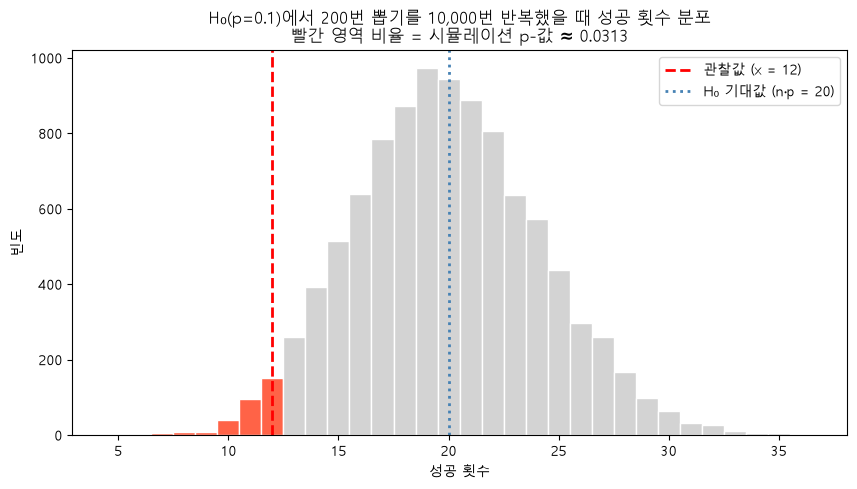

In [18]:
# [문제 1] Q5. 시뮬레이션 결과를 히스토그램으로 그려봅시다.
# 실제 관찰값(12번 성공)을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
plt.figure(figsize=(10, 5))

bins = np.arange(simulated.min(), simulated.max() + 2) - 0.5  # 정수마다 막대 하나
counts, edges, patches = plt.hist(simulated, bins=bins,
                                  color='lightgray', edgecolor='white')

# 관찰값 이하(p-값에 해당하는 영역)를 빨간색으로 강조
for patch, left in zip(patches, edges[:-1]):
    if left + 0.5 <= x:
        patch.set_facecolor('tomato')

plt.axvline(x, color='red', linestyle='--', linewidth=2,
            label=f'관찰값 (x = {x})')
plt.axvline(n * p, color='steelblue', linestyle=':', linewidth=2,
            label=f'H₀ 기대값 (n·p = {n*p:.0f})')

plt.title(f'H₀(p=0.1)에서 200번 뽑기를 {n_sim:,}번 반복했을 때 성공 횟수 분포\n'
          f'빨간 영역 비율 = 시뮬레이션 p-값 ≈ {sim_p_value:.4f}')
plt.xlabel('성공 횟수')
plt.ylabel('빈도')
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q2에서 구한 p-값은 시뮬레이션 그래프의 어느 부분에 해당하며, 무엇을 의미하나요?

- 시뮬레이션 그래프를 볼 때, 우리가 관찰한 '12회 성공'은 개발사의 주장이 맞다는 가정 하에 흔한 일인가요, 드문 일인가요?

- 이 시뮬레이션 경험을 통해 "p-값이 작으면 귀무가설을 기각한다"는 규칙을 친구에게 어떻게 더 쉽게 설명할 수 있을까요?

- 만약 200번이 아니라 1,000번을 뽑아 같은 성공률(6%)이 나왔다면, p-값은 어떻게 달라질까요?

In [ ]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.
1. p값은 시뮬레이션 그래프에서 관찰값(12회)과 그보다 왼쪽에 있는 영역의 비율에 해당한다. 
    즉 개발사 주장(10%)이 맞다면 12회 이하로 성공할 확률이 약 3%라는 뜻이다.

2. 개발사 주장(10%)이 맞다면 12회 이하가 나올 확률은 약 3%로, 드문 일이다.

3. 개발사 말대로 10%라면 200번 중 보통 20번쯤 성공해야 한다. 그중에서 12번 이하는 이런 게임에서 100번 중 3번 즉 3%밖에 안 나온다
이렇게 드문 일이 실제로 일어났으니 이는 운이 나쁘다고 보기보다 10%보다 낮다고 의심하는 것이 합리적이다.
따라서 p값이 작으면 귀무가설을 기각한다는 의미이다.


4. 성공률은 같다고 하더라고 시행 횟수가 늘어나게 되면 우연에 의한 변동이 줄어들게 된다. 이는 표준오차 공식에서 확인할 수 있따. 
    따라서 6%는 10%가정에서 200번일때보다 1000번일 때 훨씬 더 드문 결과값이 된다. 그러므로 p값은 훨씬 작아진다. 
    즉 같은 차이일지라도 표본이 클수록 더 확실한 증거가 된다.(표본이 커질 수록 나올 수 있는 결과의 범위가 줄어듦)

# 문제 2. 과자 한 봉지의 중량은 150g이 맞을까? (난이도: 하)

**📘 문제**

- 한 식품 공장에서 생산하는 과자 한 봉지의 **목표 중량은 150g**입니다.

- 품질관리팀은 생산 공정이 목표 중량을 잘 맞추고 있는지 확인하기 위해,
  생산된 과자 **30봉지를 무작위로 추출**하여 무게를 측정했습니다.

- 이번 실습에서는 **일표본 t-검정(One-sample t-Test)**으로 표본 평균이 목표 중량과 유의미하게 다른지 검증하고,
  **"평균이 정확히 150g이라면"** 어떤 표본 평균들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

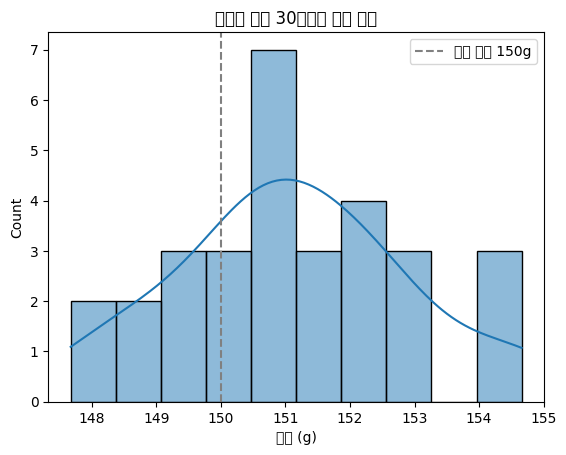

In [8]:
# 데이터 생성 (과자 30봉지의 무게 측정값)
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)
pop_mean = 150  # 목표 중량 (모평균)

# 표본 분포 시각화
sns.histplot(sample_weights, bins=10, kde=True)
plt.axvline(x=pop_mean, color='gray', linestyle='--', label='목표 중량 150g')
plt.title("추출한 과자 30봉지의 무게 분포")
plt.xlabel("무게 (g)")
plt.legend()
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 일표본 t-검정을 수행하여 t-통계량과 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"평균 무게가 정확히 150g이라면"** 30개짜리 표본의 평균이 어떻게 분포하는지 10,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 표본 평균이 그 분포에서 어디에 위치하는지 관찰해 봅시다.

In [ ]:
# [문제 2] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 과자 한 봉지의 평균 무게는 150g이다
# H₁ (대립가설): 과자 한 봉지의 평균 무게는 150g이 아니다

In [9]:
# [문제 2] Q2. 일표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_1samp

# 데이터 생성 (과자 30봉지의 무게 측정값)
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)
pop_mean = 150  # 목표 중량 (모평균)
# 여기에 코드를 작성해주세요.
t_stat, p_value = ttest_1samp(sample_weights, popmean=pop_mean)  # 기본값이 양측검정

print(f"표본 평균: {sample_weights.mean():.2f}g")   # 약 151.12g
print(f"t-통계량: {t_stat:.4f}")                    # 약 3.42
print(f"p-값: {p_value:.4f}")                       # 약 0.0019

표본 평균: 151.12g
t-통계량: 3.4193
p-값: 0.0019


In [10]:
# [문제 2] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# alpha = 0.05

# 여기에 코드를 작성해주세요.
alpha = 0.05

if p_value < alpha:
    print(f"p-값({p_value:.4f}) < {alpha} → 귀무가설 기각")
    print("결론: 과자의 평균 중량이 목표 중량 150g과 다르다고 볼 통계적 근거가 있다.")
else:
    print(f"p-값({p_value:.4f}) ≥ {alpha} → 귀무가설 기각 실패")
    print("결론: 과자의 평균 중량이 150g과 다르다고 볼 근거가 부족하다.")

p-값(0.0019) < 0.05 → 귀무가설 기각
결론: 과자의 평균 중량이 목표 중량 150g과 다르다고 볼 통계적 근거가 있다.


In [11]:
# [문제 2] Q4. H₀가 사실(평균 = 150g)이라고 가정하고, 30개짜리 표본을 10,000번 뽑아
# 각 표본의 평균을 리스트에 저장해봅시다.
# 힌트: 표준편차는 우리가 가진 표본의 표준편차를 사용한다고 가정하고, for 반복문을 사용해보세요.

# 여기에 코드를 작성해주세요.
sample_std = sample_weights.std(ddof=1)   # 표본 표준편차 (약 1.80)
n = len(sample_weights)                   # 30
n_sim = 10000

sim_means = []
for _ in range(n_sim):
    # 평균이 정확히 150g인 공정에서 30봉지를 뽑는다
    sim_sample = np.random.normal(loc=pop_mean, scale=sample_std, size=n)
    sim_means.append(sim_sample.mean())

sim_means = np.array(sim_means)

# 양측: 150g에서 관찰값만큼(또는 더) 멀리 떨어진 표본 평균의 비율
observed_mean = sample_weights.mean()
diff = abs(observed_mean - pop_mean)
sim_p_value = np.mean(np.abs(sim_means - pop_mean) >= diff)

print(f"시뮬레이션 표본 평균들의 범위: {sim_means.min():.2f} ~ {sim_means.max():.2f}g")
print(f"시뮬레이션 p-값: {sim_p_value:.4f}")   # 약 0.0006

시뮬레이션 표본 평균들의 범위: 148.86 ~ 151.34g
시뮬레이션 p-값: 0.0006


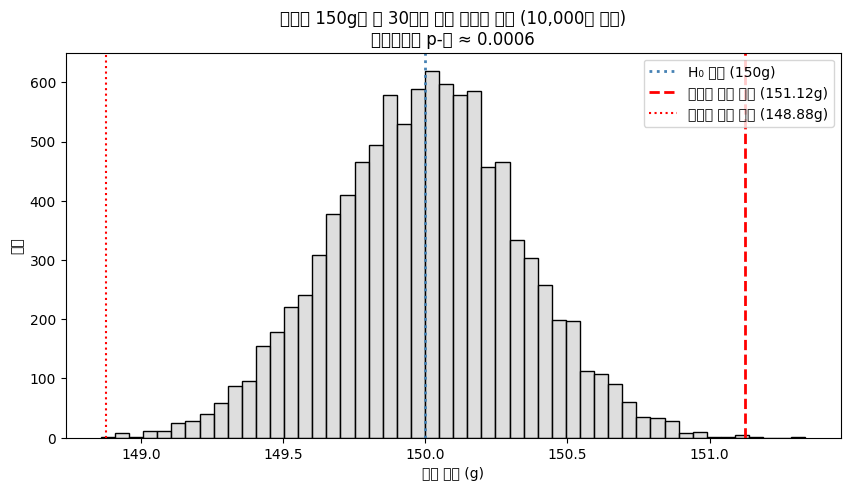

In [12]:
# [문제 2] Q5. 시뮬레이션으로 얻은 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 표본 평균을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
plt.figure(figsize=(10, 5))
sns.histplot(sim_means, bins=50, color='lightgray')

plt.axvline(pop_mean, color='steelblue', linestyle=':', linewidth=2,
            label=f'H₀ 평균 ({pop_mean}g)')
plt.axvline(observed_mean, color='red', linestyle='--', linewidth=2,
            label=f'관찰된 표본 평균 ({observed_mean:.2f}g)')
plt.axvline(pop_mean - diff, color='red', linestyle=':', linewidth=1.5,
            label=f'반대쪽 대응 위치 ({pop_mean - diff:.2f}g)')

plt.title(f'평균이 150g일 때 30봉지 표본 평균의 분포 ({n_sim:,}번 반복)\n'
          f'시뮬레이션 p-값 ≈ {sim_p_value:.4f}')
plt.xlabel('표본 평균 (g)')
plt.ylabel('빈도')
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q5의 히스토그램은 무엇을 나타내나요? 이 분포의 모양이 정규분포와 비슷한 이유는 무엇일까요? (힌트: 4장에서 배운 중심극한정리)

- 우리가 실제로 관찰한 표본 평균(세로선)은 이 분포에서 흔하게 나타나는 값인가요? Q2의 p-값과 이 시각적 위치는 어떻게 관련되나요?

- 만약 p-값이 0.001이었다면, 세로선은 그래프의 어디쯤에 위치할 것으로 예상되나요?

- 이 결과는 공장 입장에서 어떤 조치를 취해야 함을 시사할까요? (목표보다 무겁게 나오는 것은 어떤 손실일까요?)

In [ ]:
# [문제 2] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.
1. Q5의 히스토그램은 평균이 정확히 150g인 공정에서 30봉지씩 뽑았을 때 나올 수 있는 표본 평균들의 분포(표본평균의 표본분포)를 나타낸다. 
    중심극한정리에 따르면 표본 크기가 충분히 크면(보통 30 이상) 모집단 모양과 상관없이 표본평균의 분포가 정규분포에 가까워지므로, 이 분포도 150g을 중심으로 한 종 모양이 된다.

2. 관찰된 표본 평균은 분포의 오른쪽 끝에 있어 흔하지 않은 값이다. Q2의 p값은 이 세로선보다 바깥쪽(양측이므로 반대쪽 대응 위치 바깥까지 포함) 영역의 넓이에 해당한다. 
    세로선이 중심(150g)에서 멀리 있을수록 바깥 넓이가 작아지므로 p값도 작아진다.
    
3. p값 0.001은 현재 p값(약 0.0019)보다 작으므로, 세로선은 지금보다 150g에서 조금 더 먼 오른쪽(약 151.2g), 분포의 더 끝부분에 위치할 것이다. 
    (양측검정이므로 양쪽 꼬리 넓이를 합쳐서 0.001이 되는 위치)

4. 평균 중량이 목표보다 약 1.1g 무겁다는 것은 매 봉지마다 원재료를 더 넣어 그만큼 더 주고 있다는 뜻이다. 
    한 봉지에서는 작아 보여도 하루 수만~수십만 봉지가 생산되면 원가 손실이 커진다. 따라서 충전 기계를 점검하고 재보정해서 평균을 150g에 맞춰야 한다.

# 문제 3. 어떤 온라인 학습 방식이 더 효과적일까? (난이도: 중)

**📘 문제**

- 한 교육 기업에서 두 가지 다른 온라인 학습 방식(A, B)을 개발했습니다.

- 방식 A가 방식 B보다 학생들의 성적 향상에 더 효과적인지 알아보기 위해,
  두 그룹의 학생들에게 각각 다른 방식으로 한 달간 학습시킨 후 시험을 보게 했습니다.

- 이번 실습에서는 **이표본 t-검정(Two-sample t-Test)**으로 두 방식의 평균 점수 차이를 검증합니다.
  단, t-검정의 기본 가정인 **정규성**과 **등분산성**을 먼저 확인해야 합니다.

- 또한 **"두 방식의 효과가 완전히 똑같다면"** 우연히 나타날 수 있는 점수 차이의 범위를 시뮬레이션으로 확인해 봅니다.

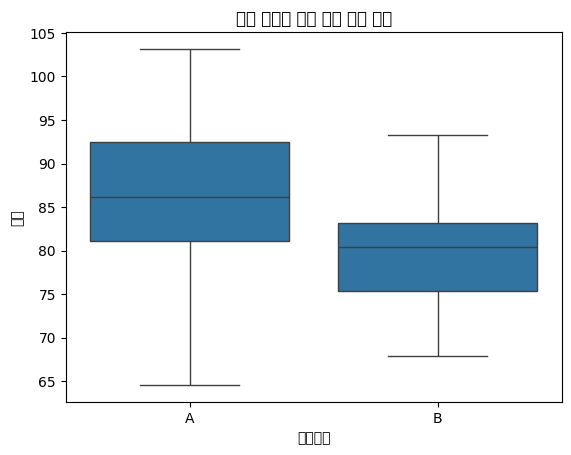

In [13]:
# 데이터 생성 (두 학습 방식의 시험 점수)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)

df_scores = pd.DataFrame({'점수': np.concatenate([group_a_scores, group_b_scores]),
                          '학습방식': ['A']*50 + ['B']*50})

# 두 그룹의 점수 분포 시각화
sns.boxplot(x='학습방식', y='점수', data=df_scores)
plt.title("학습 방식에 따른 시험 점수 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 두 그룹에 대해 **정규성 검정(Shapiro-Wilk test)**을 수행해 봅시다. (H₀: 데이터는 정규분포를 따른다.)

- **등분산성 검정(Levene's test)**을 수행해 봅시다. (H₀: 두 그룹의 분산은 같다.)

- 가정 검토 결과에 따라 `equal_var` 인수를 설정하여 **이표본 t-검정**을 수행해 봅시다.

- 두 그룹 데이터를 모두 합친 뒤 무작위로 다시 나누는 방식으로, **"두 방식의 효과가 같을 때"**의 평균 차이 분포를 시뮬레이션해 봅시다.

In [14]:
# [문제 3] Q1. 두 그룹에 대해 각각 정규성 검정(Shapiro-Wilk test)을 수행하고 p-값을 출력해봅시다.
# H₀: 데이터는 정규분포를 따른다.

# 여기에 코드를 작성해주세요.
# H₀: 데이터는 정규분포를 따른다.
_, p_norm_a = stats.shapiro(group_a_scores)
_, p_norm_b = stats.shapiro(group_b_scores)

print(f"A그룹 정규성 p-값: {p_norm_a:.4f}")
print(f"B그룹 정규성 p-값: {p_norm_b:.4f}")

if p_norm_a > alpha and p_norm_b > alpha:
    print("→ 두 그룹 모두 H₀ 기각 실패: 정규성 가정을 만족한다고 본다.")
else:
    print("→ 정규성 가정 위배 가능성 (비모수 검정인 Mann-Whitney U 검정 고려)")

A그룹 정규성 p-값: 0.8766
B그룹 정규성 p-값: 0.8366
→ 두 그룹 모두 H₀ 기각 실패: 정규성 가정을 만족한다고 본다.


In [15]:
# [문제 3] Q2. 두 그룹에 대해 등분산성 검정(Levene's test)을 수행하고 p-값을 출력해봅시다.
# H₀: 두 그룹의 분산은 같다.

# 여기에 코드를 작성해주세요.
# H₀: 두 그룹의 분산은 같다.
_, p_levene = stats.levene(group_a_scores, group_b_scores)
print(f"Levene 검정 p-값: {p_levene:.4f}")

equal_var = p_levene > alpha   # 기각 못 하면 등분산 가정
print(f"→ 등분산 가정: {equal_var}")

Levene 검정 p-값: 0.0150
→ 등분산 가정: False


In [16]:
# [문제 3] Q3. 이표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.
# H₀: 두 그룹의 평균은 같다. / H₁: 두 그룹의 평균은 다르다.
# 등분산성 가정을 만족했는지 여부에 따라 equal_var 인수를 설정해보세요.

# 여기에 코드를 작성해주세요.
# H₀: 두 그룹의 평균은 같다. / H₁: 두 그룹의 평균은 다르다.
alpha = 0.05

# 등분산성 검정 결과에 따라 equal_var 설정
_, p_levene = stats.levene(group_a_scores, group_b_scores)
equal_var = p_levene > alpha   # p ≈ 0.015 → False (등분산 기각)

test_name = "Student t-검정" if equal_var else "Welch t-검정"
print(f"Levene p-값: {p_levene:.4f} → equal_var={equal_var} → {test_name} 사용")

t_stat, p_value = stats.ttest_ind(group_a_scores, group_b_scores, equal_var=equal_var)

print(f"A그룹 평균: {group_a_scores.mean():.2f}점, B그룹 평균: {group_b_scores.mean():.2f}점")
print(f"t-통계량: {t_stat:.4f}")   # 약 4.04
print(f"p-값: {p_value:.4f}")       # 약 0.0001

if p_value < alpha:
    print("→ 귀무가설 기각: 두 학습 방식의 평균 점수에 유의미한 차이가 있다.")
else:
    print("→ 귀무가설 기각 실패: 두 방식의 평균 점수 차이가 유의미하다고 보기 어렵다.")

Levene p-값: 0.0150 → equal_var=False → Welch t-검정 사용
A그룹 평균: 86.12점, B그룹 평균: 79.85점
t-통계량: 4.0426
p-값: 0.0001
→ 귀무가설 기각: 두 학습 방식의 평균 점수에 유의미한 차이가 있다.


In [17]:
# [문제 3] Q4. H₀가 사실(두 그룹의 평균이 같다)이라고 가정하고 시뮬레이션을 10,000번 수행해봅시다.
# 두 그룹의 데이터를 모두 합친 뒤(np.concatenate), 매 반복마다 비복원추출로 50개(가상 A그룹)와
# 나머지 50개(가상 B그룹)로 나누어 두 그룹의 평균 차이를 계산하고 리스트에 저장해보세요.
# 힌트: np.random.permutation 을 사용해보세요.

# 여기에 코드를 작성해주세요.
# 실제 관찰된 평균 차이
observed_diff = group_a_scores.mean() - group_b_scores.mean()   # 약 6.27점

# 효과가 같다면 A/B 이름표는 의미 없음 → 100명 점수를 하나로 합침
combined = np.concatenate([group_a_scores, group_b_scores])
n_a = len(group_a_scores)   # 50
n_sim = 10000

sim_diffs = []
for _ in range(n_sim):
    shuffled = np.random.permutation(combined)   # 무작위로 섞기 (비복원추출)
    fake_a = shuffled[:n_a]                      # 앞 50명 → 가상 A그룹
    fake_b = shuffled[n_a:]                      # 나머지 50명 → 가상 B그룹
    sim_diffs.append(fake_a.mean() - fake_b.mean())

sim_diffs = np.array(sim_diffs)

# 양측: 0에서 관찰값만큼(또는 더) 멀리 떨어진 차이의 비율
sim_p_value = np.mean(np.abs(sim_diffs) >= abs(observed_diff))

print(f"관찰된 평균 차이: {observed_diff:.2f}점")
print(f"시뮬레이션 평균 차이 범위: {sim_diffs.min():.2f} ~ {sim_diffs.max():.2f}점")
print(f"시뮬레이션 p-값: {sim_p_value:.4f}")   # 약 0.0001 (거의 0)

관찰된 평균 차이: 6.27점
시뮬레이션 평균 차이 범위: -6.17 ~ 6.61점
시뮬레이션 p-값: 0.0001


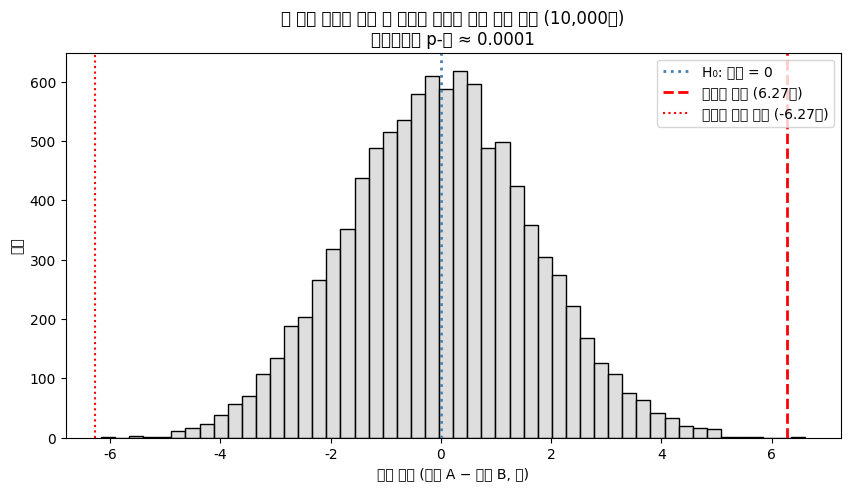

In [18]:
# [문제 3] Q5. 시뮬레이션으로 얻은 평균 차이의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 평균 차이(A그룹 평균 - B그룹 평균)를 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
plt.figure(figsize=(10, 5))
sns.histplot(sim_diffs, bins=50, color='lightgray')

plt.axvline(0, color='steelblue', linestyle=':', linewidth=2, label='H₀: 차이 = 0')
plt.axvline(observed_diff, color='red', linestyle='--', linewidth=2,
            label=f'관찰된 차이 ({observed_diff:.2f}점)')
plt.axvline(-observed_diff, color='red', linestyle=':', linewidth=1.5,
            label=f'반대쪽 대응 위치 ({-observed_diff:.2f}점)')

plt.title(f'두 방식 효과가 같을 때 우연히 생기는 평균 차이 분포 ({n_sim:,}번)\n'
          f'시뮬레이션 p-값 ≈ {sim_p_value:.4f}')
plt.xlabel('평균 차이 (가상 A − 가상 B, 점)')
plt.ylabel('빈도')
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 정규성 검정과 등분산성 검정의 p-값은 각각 어떻게 해석해야 하나요? 이 결과는 이표본 t-검정을 사용하는 데 문제가 없음을 보여주나요?

- Q5의 히스토그램 중심이 0에 가까운 이유는 무엇일까요?

- 실제 관찰된 평균 차이(세로선)는 "두 방식의 효과가 같다"고 가정했을 때 우연히 나타날 수 있는 범위 안에 있나요, 벗어나나요?

- 이 시각적 판단과 Q3의 p-값은 어떤 관계가 있나요?

- 통계적으로 유의미한 차이가 있다면, 교육 기업은 이 결과를 어떻게 활용할 수 있을까요?

In [ ]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.
1. A그룹(p ≈ 0.877)과 B그룹(p ≈ 0.837) 모두 정규성 검정의 p값이 0.05보다 커서 정규분포를 따르지 않는다는 증거가 없다. 
    따라서 정규성 가정에는 문제가 없다. 반면 Levene 검정 p값(약 0.015)은 0.05보다 작아서 등분산 가정이 기각된다. 
    결론적으로 일반 t-검정(Student)은 적절하지 않고, 분산이 달라도 쓸 수 있는 Welch t-검정을 사용하면 문제가 없다

2. 시뮬레이션은 두 방식의 효과가 같다고 가정하고, A/B 이름표를 무시한 채 점수를 섞어 무작위로 나눴다. 
    이렇게 나누면 어느 쪽 그룹이 더 높을 이유가 없으므로 평균 차이가 양수일 때와 음수일 때가 비슷하게 나온다. 
    따라서 차이의 분포는 0을 중심으로 좌우 대칭이 된다.

3. 시뮬레이션으로 얻은 평균 차이는 대부분 0을 중심으로 몰려 있다. 실제로 관찰된 차이는 이 분포의 바깥에 있어서 두 방식의 효과가 같을 때 우연히 나타날 수 있는 범위를 벗어난다.
    10,000번 중 이만큼 큰 차이가 나온 경우는 거의 없었다.

4. 세로선(그리고 반대쪽 대응 위치)의 바깥 넓이가 p값이다. 세로선이 0에서 멀리 떨어질수록 바깥 넓이가 작아져 p값도 작아진다. 
    실제로 세로선이 분포 끝 바깥에 있다는 시각적 판단과 Q3의 p값이 매우 작다는 결과는 같은 내용을 말한다.

5. 방식 a를 기본 학습 방식으로 채택하거나 b이용자에게 확대 적용하는 식으로 서비스를 개선할 수 있고,
이 결과 값을 데이터 기반 홍보 자료로 활용할 수 있다.

# 문제 4. 연령대별로 선호하는 영화 장르가 다를까? (난이도: 중)

**📘 문제**

- 한 영화관에서 고객의 **연령대(20대, 30대, 40대)**에 따라 선호하는 **영화 장르(액션, 로맨스)**에 차이가 있는지 궁금해졌습니다.

- 이를 알아보기 위해 300명의 고객을 대상으로 설문조사를 진행하여 분할표를 얻었습니다.

- 이번 실습에서는 **카이제곱 독립성 검정(Chi-squared Test of Independence)**으로
  두 범주형 변수 사이에 연관성이 있는지 검증합니다.

- 또한 **"두 변수가 서로 아무 관련이 없다면(독립이라면)"** 어떤 카이제곱 통계량들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

관측 빈도 (Observed Frequencies):
      액션  로맨스
20대    70      30
30대    50      60
40대    30      60


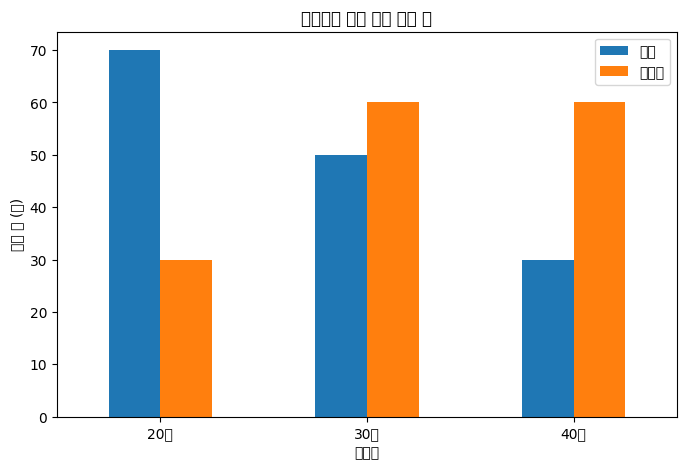

In [19]:
# 데이터 생성 (관측 빈도 분할표)
data = {'액션': [70, 50, 30],
        '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])

print("관측 빈도 (Observed Frequencies):")
print(observed)

# 분할표 시각화
observed.plot(kind='bar', figsize=(8, 5))
plt.title("연령대별 선호 장르 응답 수")
plt.xlabel("연령대")
plt.ylabel("응답 수 (명)")
plt.xticks(rotation=0)
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 카이제곱 독립성 검정을 수행하여 카이제곱 통계량, p-값, 자유도, **기대 빈도**를 구해봅시다.

- **"연령대와 선호 장르가 독립이라면"** 어떤 분할표들이 나타날 수 있는지 5,000번 시뮬레이션해 봅시다.

- 시뮬레이션으로 얻은 카이제곱 통계량 분포와 실제 관찰된 카이제곱 통계량을 비교해 봅시다.

In [ ]:
# [문제 4] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 연령대와 선호영화장르는 서로 독립이다.
# H₁ (대립가설): 연령대와 선호영화장르는 서로 독립이 아니다.

In [20]:
# [문제 4] Q2. 카이제곱 독립성 검정을 수행하고 카이제곱 통계량, p-값, 자유도, 기대 빈도를 구해봅시다.
# 기대 빈도는 관측 빈도와 비교하기 쉽도록 데이터프레임 형태로 출력해보세요.

# 여기에 코드를 작성해주세요.
chi2_stat, p_value, dof, expected = stats.chi2_contingency(observed)

# 기대 빈도를 관측 빈도와 같은 형태의 데이터프레임으로 변환
expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns)

print(f"카이제곱 통계량: {chi2_stat:.4f}")   # 약 26.91
print(f"p-값: {p_value:.8f}")                # 약 0.0000014
print(f"자유도: {dof}")                      # (3-1) × (2-1) = 2
print("\n기대 빈도 (Expected Frequencies):")
print(expected_df)

alpha = 0.05
if p_value < alpha:
    print("\n→ 귀무가설 기각: 연령대에 따라 선호 장르에 유의미한 차이가 있다.")
else:
    print("\n→ 귀무가설 기각 실패: 연령대에 따라 선호 장르가 다르다고 보기 어렵다.")

카이제곱 통계량: 26.9091
p-값: 0.00000143
자유도: 2

기대 빈도 (Expected Frequencies):
      액션  로맨스
20대  50.0    50.0
30대  55.0    55.0
40대  45.0    45.0

→ 귀무가설 기각: 연령대에 따라 선호 장르에 유의미한 차이가 있다.


In [22]:
# [문제 4] Q3. H₀가 사실(두 변수가 독립)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 각 반복마다 300명의 가상 고객에게 연령대와 장르를 '독립적으로' 할당한 후,
# 가상 분할표를 만들고 카이제곱 통계량을 계산하여 리스트에 저장해보세요.
# 힌트 1: 전체 비율(observed.sum(axis=0) / 전체, observed.sum(axis=1) / 전체)을 확률로 사용
# 힌트 2: np.random.choice 로 300명의 연령대와 장르를 각각 독립적으로 생성
# 힌트 3: pd.crosstab 으로 분할표 생성 후 stats.chi2_contingency 로 통계량 계산

# 여기에 코드를 작성해주세요.
N = observed.values.sum()                    # 300명
age_prob = observed.sum(axis=1) / N          # 연령대 비율 (20대 1/3, 30대 11/30, 40대 0.3)
genre_prob = observed.sum(axis=0) / N        # 장르 비율 (액션 0.5, 로맨스 0.5)

n_sim = 5000
sim_chi2 = []

for _ in range(n_sim):
    # 연령대와 장르를 '따로따로' 뽑는다 → 서로 아무 관련이 없게 만듦 (독립)
    fake_age = np.random.choice(age_prob.index, size=N, p=age_prob.values)
    fake_genre = np.random.choice(genre_prob.index, size=N, p=genre_prob.values)

    # 가상 분할표 (혹시 빠진 범주가 있어도 0으로 채워 3×2 유지)
    fake_table = pd.crosstab(fake_age, fake_genre).reindex(
        index=observed.index, columns=observed.columns, fill_value=0)

    stat, _, _, _ = stats.chi2_contingency(fake_table)
    sim_chi2.append(stat)

sim_chi2 = np.array(sim_chi2)

# 카이제곱은 '차이의 크기'라 오른쪽 꼬리만 봄
sim_p_value = np.mean(sim_chi2 >= chi2_stat)

print(f"시뮬레이션 카이제곱 평균: {sim_chi2.mean():.2f}")       # 약 2 (= 자유도)
print(f"시뮬레이션 카이제곱 최댓값: {sim_chi2.max():.2f}")      # 약 17
print(f"시뮬레이션 p-값: {sim_p_value:.8f}")                    # 0.0000

시뮬레이션 카이제곱 평균: 2.01
시뮬레이션 카이제곱 최댓값: 17.91
시뮬레이션 p-값: 0.00000000


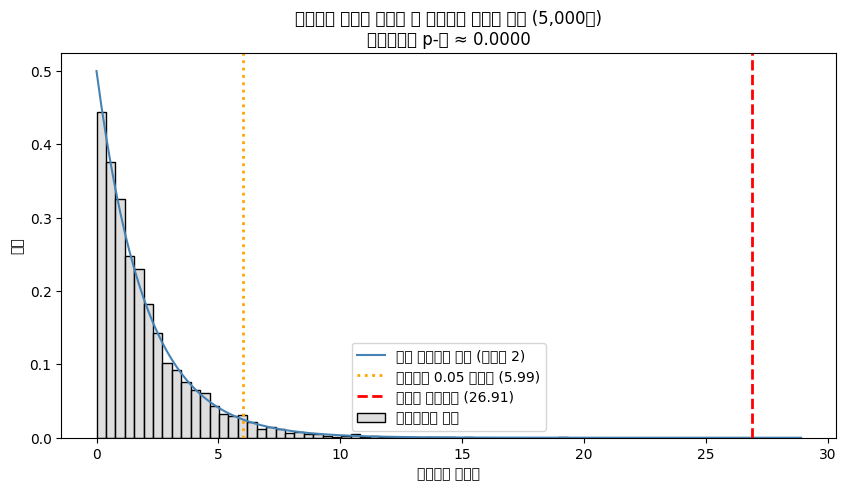

In [21]:
# [문제 4] Q4. 시뮬레이션으로 얻은 카이제곱 통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 카이제곱 통계량을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
crit = stats.chi2.ppf(1 - alpha, dof)   # 유의수준 0.05 임계값 (약 5.99)

plt.figure(figsize=(10, 5))
sns.histplot(sim_chi2, bins=50, stat='density', color='lightgray', label='시뮬레이션 결과')

# 이론적인 카이제곱 분포(자유도 2)도 함께 그려 비교
x_line = np.linspace(0, max(chi2_stat, sim_chi2.max()) + 2, 300)
plt.plot(x_line, stats.chi2.pdf(x_line, dof), color='steelblue',
         label=f'이론 카이제곱 분포 (자유도 {dof})')

plt.axvline(crit, color='orange', linestyle=':', linewidth=2,
            label=f'유의수준 0.05 임계값 ({crit:.2f})')
plt.axvline(chi2_stat, color='red', linestyle='--', linewidth=2,
            label=f'관찰된 카이제곱 ({chi2_stat:.2f})')

plt.title(f'연령대와 장르가 독립일 때 카이제곱 통계량 분포 ({n_sim:,}번)\n'
          f'시뮬레이션 p-값 ≈ {sim_p_value:.4f}')
plt.xlabel('카이제곱 통계량')
plt.ylabel('밀도')
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- '기대 빈도'는 어떤 의미를 가지며, '관측 빈도'와의 차이가 클수록 카이제곱 통계량은 어떻게 변할까요?

- Q4의 히스토그램은 어떤 분포를 시각화한 것인가요? 실제 관찰된 카이제곱 통계량(세로선)은 흔한 값인가요, 극단적인 값인가요?

- 유의수준 0.05에서, 연령대와 선호 장르 사이에 통계적으로 유의미한 연관성이 있다고 결론 내릴 수 있나요? 그 이유는 무엇인가요?

- 이 결과를 바탕으로 영화관은 연령대별로 어떤 상영 전략이나 프로모션을 세울 수 있을까요?

In [ ]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

1. 기대 빈도는 연령대와 선호 장르가 서로 독립이라면 각 칸에 나올 것으로 예상되는 빈도이다. 
카이제곱 통계량은 각 칸의 (관측 − 기대)² / 기대를 모두 더한 값이므로, 관측 빈도와 기대 빈도의 차이가 클수록 카이제곱 통계량은 커진다.

2. Q4의 히스토그램은 연령대와 선호 장르가 독립일 때 우연히 나올 수 있는 카이제곱 통계량의 분포를 시각화한 것이다.(자유도 2인 카이제곱 분포와 거의 일치한다.) 
    이 분포는 대부분 0~6 사이에 몰려 있는데, 실제 관찰값(약 26.91)은 시뮬레이션 최댓값(약 17)보다도 오른쪽에 있으므로 매우 극단적인 값이다.

3. 카이제곱 통계량(약 26.91)이 유의수준 0.05의 임계값보다 훨씬 크고, p값(약 0.0000014)이 0.05보다 작으므로 귀무가설을 기각한다. 
    따라서 연령대와 선호 장르 사이에 통계적으로 유의미한 연관성이 있다고 결론 내릴 수 있다.

4. 20대: 액션 영화 위주로 홍보하고, 대학생 할인이나 심야 액션 상영 같은 프로모션을 진행한다.
    40대: 로맨스 영화를 주말 낮이나 평일 저녁 시간대에 배치하고, 부부 동반 할인 같은 프로모션을 진행한다.
    -> 각 연령대가 많이 방문하는 시간대에 맞춰 상영관 배정과 상영 횟수를 조정한다.

# 문제 5. 미니 프로젝트 - 어떤 신규 비료가 가장 효과적일까? (난이도: 상)

**📘 문제**

- 한 농업 연구소에서 새로 개발한 비료 3종류(A, B, C)의 생산량 증대 효과를 비교하고자 합니다.

- 동일한 조건의 밭 30개를 준비하여, 각각 10개씩 비료 A, B, C를 투여한 후 수확량을 측정했습니다.

- 이번 실습에서는 **분산분석(ANOVA)**으로 세 비료 간 평균 수확량에 차이가 있는지 검증하고,
  차이가 있다면 **사후분석(Tukey's HSD)**으로 어떤 비료끼리 차이가 나는지 확인합니다.

- 마지막으로 **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량이 나올 수 있는지 시뮬레이션하고,
  분석 결과를 바탕으로 연구소에 어떤 비료를 추천할지까지 생각해 봅니다.

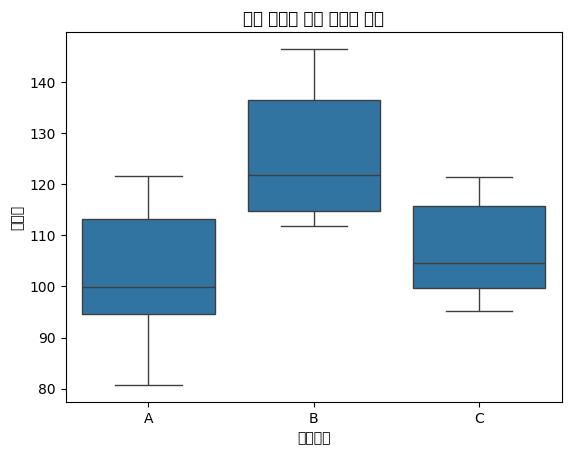

In [23]:
# 데이터 생성 (비료 종류별 수확량)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)

# 데이터프레임으로 변환 (사후분석을 위해)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})

# 데이터 탐색 시각화
sns.boxplot(x='비료종류', y='수확량', data=df)
plt.title("비료 종류에 따른 수확량 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 세 그룹에 대해 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.

- ANOVA 결과가 유의미할 경우에만 **Tukey's HSD 사후분석**을 수행하고 결과를 해석해 봅시다.

- **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량들이 나오는지 5,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 F-통계량이 얼마나 극단적인 값인지 확인해 봅시다.

- 분석 결과를 종합하여 연구소에 추천할 비료를 정해 봅시다.

In [24]:
# [문제 5] Q1. 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.
# H₀: 세 비료의 평균 수확량은 모두 같다.
# H₁: 적어도 하나 이상의 비료 평균 수확량은 다르다.
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
# 여기에 코드를 작성해주세요.

f_stat, p_value = stats.f_oneway(fertilizer_a, fertilizer_b, fertilizer_c)

print(df.groupby('비료종류')['수확량'].agg(['mean', 'std']).round(2))
print(f"\nF-통계량: {f_stat:.4f}")   # 약 10.35
print(f"p-값: {p_value:.4f}")        # 약 0.0005

            mean    std
비료종류               
A         102.30  13.03
B         125.98  13.75
C         107.15   9.74

F-통계량: 10.3455
p-값: 0.0005


In [25]:
# [문제 5] Q2. ANOVA의 p-값이 유의수준 0.05보다 작을 경우에만
# Tukey's HSD 사후분석을 수행하고 결과를 출력해봅시다.
# 힌트: pairwise_tukeyhsd(endog=수확량, groups=비료종류, alpha=0.05)

# 여기에 코드를 작성해주세요.
if p_value < alpha:
    print(f"ANOVA p-값({p_value:.4f}) < {alpha} → 귀무가설 기각, 사후분석 수행\n")
    tukey = pairwise_tukeyhsd(endog=df['수확량'], groups=df['비료종류'], alpha=alpha)
    print(tukey)
else:
    print(f"ANOVA p-값({p_value:.4f}) ≥ {alpha} → 귀무가설 기각 실패, 사후분석 불필요")

ANOVA p-값(0.0005) < 0.05 → 귀무가설 기각, 사후분석 수행

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B  23.6754 0.0006  10.0402 37.3106   True
     A      C   4.8429 0.6569  -8.7923 18.4781  False
     B      C -18.8325 0.0054 -32.4677 -5.1972   True
-----------------------------------------------------


In [26]:
# [문제 5] Q3. H₀가 사실(세 그룹의 평균이 모두 같다)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 모든 데이터를 합친 평균과 표준편차를 가진 H₀ 모집단에서 10개씩 3개의 가상 그룹을 생성하고,
# 이 가상 그룹들로 ANOVA를 수행하여 F-통계량을 리스트에 저장해보세요.

# 여기에 코드를 작성해주세요.
all_yield = df['수확량'].values
h0_mean = all_yield.mean()        # 전체 평균
h0_std = all_yield.std(ddof=1)    # 전체 표준편차
n_per_group = 10
n_sim = 5000

sim_f = []
for _ in range(n_sim):
    # 평균이 모두 같은 하나의 모집단에서 10개씩 3그룹 생성
    g1 = np.random.normal(h0_mean, h0_std, n_per_group)
    g2 = np.random.normal(h0_mean, h0_std, n_per_group)
    g3 = np.random.normal(h0_mean, h0_std, n_per_group)
    f, _ = stats.f_oneway(g1, g2, g3)
    sim_f.append(f)

sim_f = np.array(sim_f)

# F도 '그룹 간 차이의 크기'라서 오른쪽 꼬리만 봄
sim_p_value = np.mean(sim_f >= f_stat)

print(f"시뮬레이션 F 평균: {sim_f.mean():.2f}")       # 약 1
print(f"시뮬레이션 F 최댓값: {sim_f.max():.2f}")      # 약 10
print(f"시뮬레이션 p-값: {sim_p_value:.4f}")          # 약 0.0000

시뮬레이션 F 평균: 1.04
시뮬레이션 F 최댓값: 10.09
시뮬레이션 p-값: 0.0000


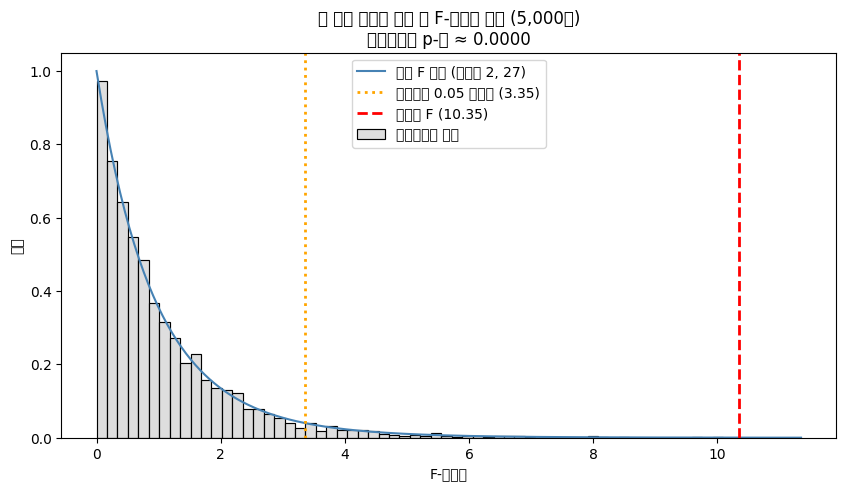

In [27]:
# [문제 5] Q4. 시뮬레이션으로 얻은 F-통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 F-통계량을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
df_between = 3 - 1                    # 그룹 간 자유도 = 2
df_within = len(all_yield) - 3        # 그룹 내 자유도 = 27
crit = stats.f.ppf(1 - alpha, df_between, df_within)   # 임계값 약 3.35

plt.figure(figsize=(10, 5))
sns.histplot(sim_f, bins=60, stat='density', color='lightgray', label='시뮬레이션 결과')

x_line = np.linspace(0, max(f_stat, sim_f.max()) + 1, 300)
plt.plot(x_line, stats.f.pdf(x_line, df_between, df_within), color='steelblue',
         label=f'이론 F 분포 (자유도 {df_between}, {df_within})')

plt.axvline(crit, color='orange', linestyle=':', linewidth=2,
            label=f'유의수준 0.05 임계값 ({crit:.2f})')
plt.axvline(f_stat, color='red', linestyle='--', linewidth=2,
            label=f'관찰된 F ({f_stat:.2f})')

plt.title(f'세 비료 효과가 같을 때 F-통계량 분포 ({n_sim:,}번)\n'
          f'시뮬레이션 p-값 ≈ {sim_p_value:.4f}')
plt.xlabel('F-통계량')
plt.ylabel('밀도')
plt.legend()
plt.show()

In [ ]:
# [문제 5] Q5. 분석 결과를 바탕으로 연구소에 어떤 비료를 추천하시겠습니까?
# 여기에 의견을 작성해주세요.

- A vs B: 차이 약 23.7, p-adj ≈ 0.0006 → 유의미 (B가 더 높음)
- B vs C: 차이 약 18.8, p-adj ≈ 0.0054 → 유의미 (B가 더 높음)
- A vs C: 차이 약 4.8,  p-adj ≈ 0.66   → 유의미하지 않음

추천: 비료b
평균 수확량이 125.98로 가장 높고 비료a와 비료b와의 차이가 모두 통계적으로 유의미하다.
따라서 가장 효과가 좋은 비료b를 사용해야 한다.

**🧠 데이터를 어떻게 읽을까요?**

- ANOVA 검정의 p-값을 통해 어떤 결론을 내릴 수 있나요? 이 결과는 "세 비료가 모두 동일한 효과를 가진다"는 뜻인가요, "적어도 하나는 다르다"는 뜻인가요?

- Tukey's HSD 결과표의 `reject` 열에서 `True`로 표시된 조합은 무엇이며, 이는 무엇을 의미하나요?

- `meandiff` 열의 값은 어떤 정보를 주나요? 신뢰구간(`lower`, `upper`)이 0을 포함하는지 여부는 무엇을 뜻할까요?

- 그룹별 표본 크기가 10개로 작다는 점은 이 결론의 신뢰도에 어떤 영향을 줄까요? 어떻게 개선할 수 있을까요?

In [ ]:
# [문제 5] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.
1. p-값이 0.0005이므로 유의수준 0.05보다 작다 따라서 이 결과는 세 비료 중 적어도 하나는 다르다는 것을 의미한다.

2. reject 열은 각 조합에서 두 그룹의 평균이 같다는 귀무가설을 기각하는지를 나타낸다.
    reject가 True인 조합은 A-B와 B-C이다. 이는 두 조합에서 평균이 같다는 귀무가설이 기각되어 평균 수확량 차이가 통계적으로 유의미하다는 뜻이다

3. meandiff는 두 그룹의 평균 차이(group2 − group1)로 차이의 크기와 방향을 알려준다. 
   신뢰구간에서 0은 두 그룹의 평균 차이가 없다, 즉 두 비료의 효과가 같다는 상태를 뜻한다. 
    신뢰구간이 0을 포함하면 실제 차이가 0일 가능성을 배제할 수 없으므로, 두 비료의 효과가 같을 수도 있어 차이가 유의미하지 않다고 본다.
    반대로 신뢰구간이 0을 포함하지 않으면 차이가 0일 가능성이 낮으므로 차이가 유의미하다고 본다

4. 그룹별 표본이 10개로 작으면 정규성 가정을 확인하기 어렵고, 검정력이 낮아 실제 차이를 놓칠 수 있으며, 
    신뢰구간이 넓어 효과의 크기를 정확히 추정하기 어렵고, 이상치 한두 개에 결과가 크게 흔들릴 수 있다.
    이는 원하는 검정력과 찾고 싶은 차이 크기를 정해 필요한 표본 수를 계산하여 늘림으로써 개선할 수 있다.